# Can a syndrome histogram justify a decoder?

Steane [[7,1,3]] memory, coherent X rotations, and separate temporal calibration. This notebook **executes Qiskit** for short repeated-correction circuits and calibration; long storage uses the independently checked logical model. See [the mathematical note](../docs/math-note.md) for derivations and citations and [the full statistical report](../results/REPORT.md) for the larger seeded run.

The [code walkthrough](../docs/code-walkthrough.md) maps equations to functions; [noise and I/O](../docs/noise-and-io.md) defines the inputs and outputs.

The known answer is preservation of any logical input. No QPU or account is used.

In [1]:
from pathlib import Path
import sys, json, csv
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'q3hack').exists()
assert Path(sys.prefix).resolve() == (ROOT / '.venv').resolve()
sys.path.insert(0, str(ROOT / 'src'))
import q3hack
assert Path(q3hack.__file__).resolve().parent == (ROOT / 'src' / 'q3hack').resolve()
import numpy as np
from IPython.display import display, Image, Markdown
from q3hack.code import STATES, codewords, encoded_state, preparation
from q3hack.logical_model import branches, physical_branches, exact_fidelity
from q3hack.circuits import storage_circuit
from qiskit.quantum_info import Statevector
print('Interpreter:', sys.executable)
import importlib.metadata as metadata
print({p: metadata.version(p) for p in ('qiskit', 'qiskit-aer', 'numpy', 'scipy')})

Interpreter: G:\qtum\q3hack-26\q3hack26-team-bells-pair\.venv\Scripts\python.exe
{'qiskit': '2.5.2', 'qiskit-aer': '0.17.2', 'numpy': '2.5.4', 'scipy': '1.18.1'}


## Which noise is present?

**Both F and R contain deliberately injected coherent rotations.** F retains one fair common sign throughout a shot; R refreshes it each interval. The sign is common to all data qubits in both models.

| Stage | Engine | Programmed noise | Added Aer NoiseModel |
|---|---|---|---|
| Ideal control | Aer shots | theta=0 | None |
| Short storage / bare control | Aer shots | F/R rotations | None |
| Separate calibration | Aer shots | Two uninterrupted F/R intervals | None |
| Sensitivity, T=4 | Aer shots | F/R rotations | 1% / 3% q7 report flips only |
| Long T=128/929 comparison | Validated logical-model samples | Ideal F/R channels | No Aer execution |

There is no device-derived model, gate error, relaxation, leakage or crosstalk. Calibration remains ideal even in the report-error sensitivity comparison.

## Read the inputs and outputs

| Symbol / field | Meaning |
|---|---|
| theta | Known angle in radians; injected gate is Rx(2 xi theta) |
| T / cycles | Number of noise-plus-correction intervals, not physical time |
| N / budget | Calibration shots per batch, reused for separate held-out storage records |
| state | One of six Pauli inputs; used for preparation/scoring, never decoder selection |
| syndrome | s0+2 s1+4 s2, an integer 0 to 7; short records have shape (shots,T) |
| nonzero_count | Number of nonzero syndromes; sufficient for this symmetric model |
| action | Final I or logical X, applied as a destructive-readout frame |
| outcome / failure | Evaluation-only measurement data; never decoder input |
| Fe / f_mean | Entanglement / six-state average fidelity; f_mean=(2Fe+1)/3 |

Standard always selects final I; independence assumes R; calibrated learns F/R; oracle knows the distribution, never the realized signs.

## Check the code and coherent branches

The input is always qubit 0; one Clifford encoder works for all six Pauli eigenstates. The 128 physical X supports are summed as amplitudes within each syndrome/logical class. An independent Qiskit statevector calculation rotates, projects, corrects, and decodes.

In [2]:
for state in STATES:
    target = codewords() @ Statevector.from_instruction(preparation(state)).data
    np.testing.assert_allclose(encoded_state(state).data, target, atol=2e-14)
residuals = []
for theta in (0.05, 0.1, 0.2):
    for sign in (-1, 1):
        physical, leakage = physical_branches(theta, sign)
        residuals.append(float(np.max(np.abs(physical-branches(theta, sign).kraus))))
        assert leakage < 1e-12 and residuals[-1] < 1e-12
print('All six encoded inputs passed; maximum branch residual:', max(residuals))

All six encoded inputs passed; maximum branch residual: 5.551115123125783e-16


## Inspect the actual repeated-correction circuit

Seven data qubits and a reusable ancilla measure the three Z checks each cycle. Distinct three-bit registers retain the history. Register-conditioned X gates perform the per-cycle correction. Final logical actions are destructive-readout Pauli frames.

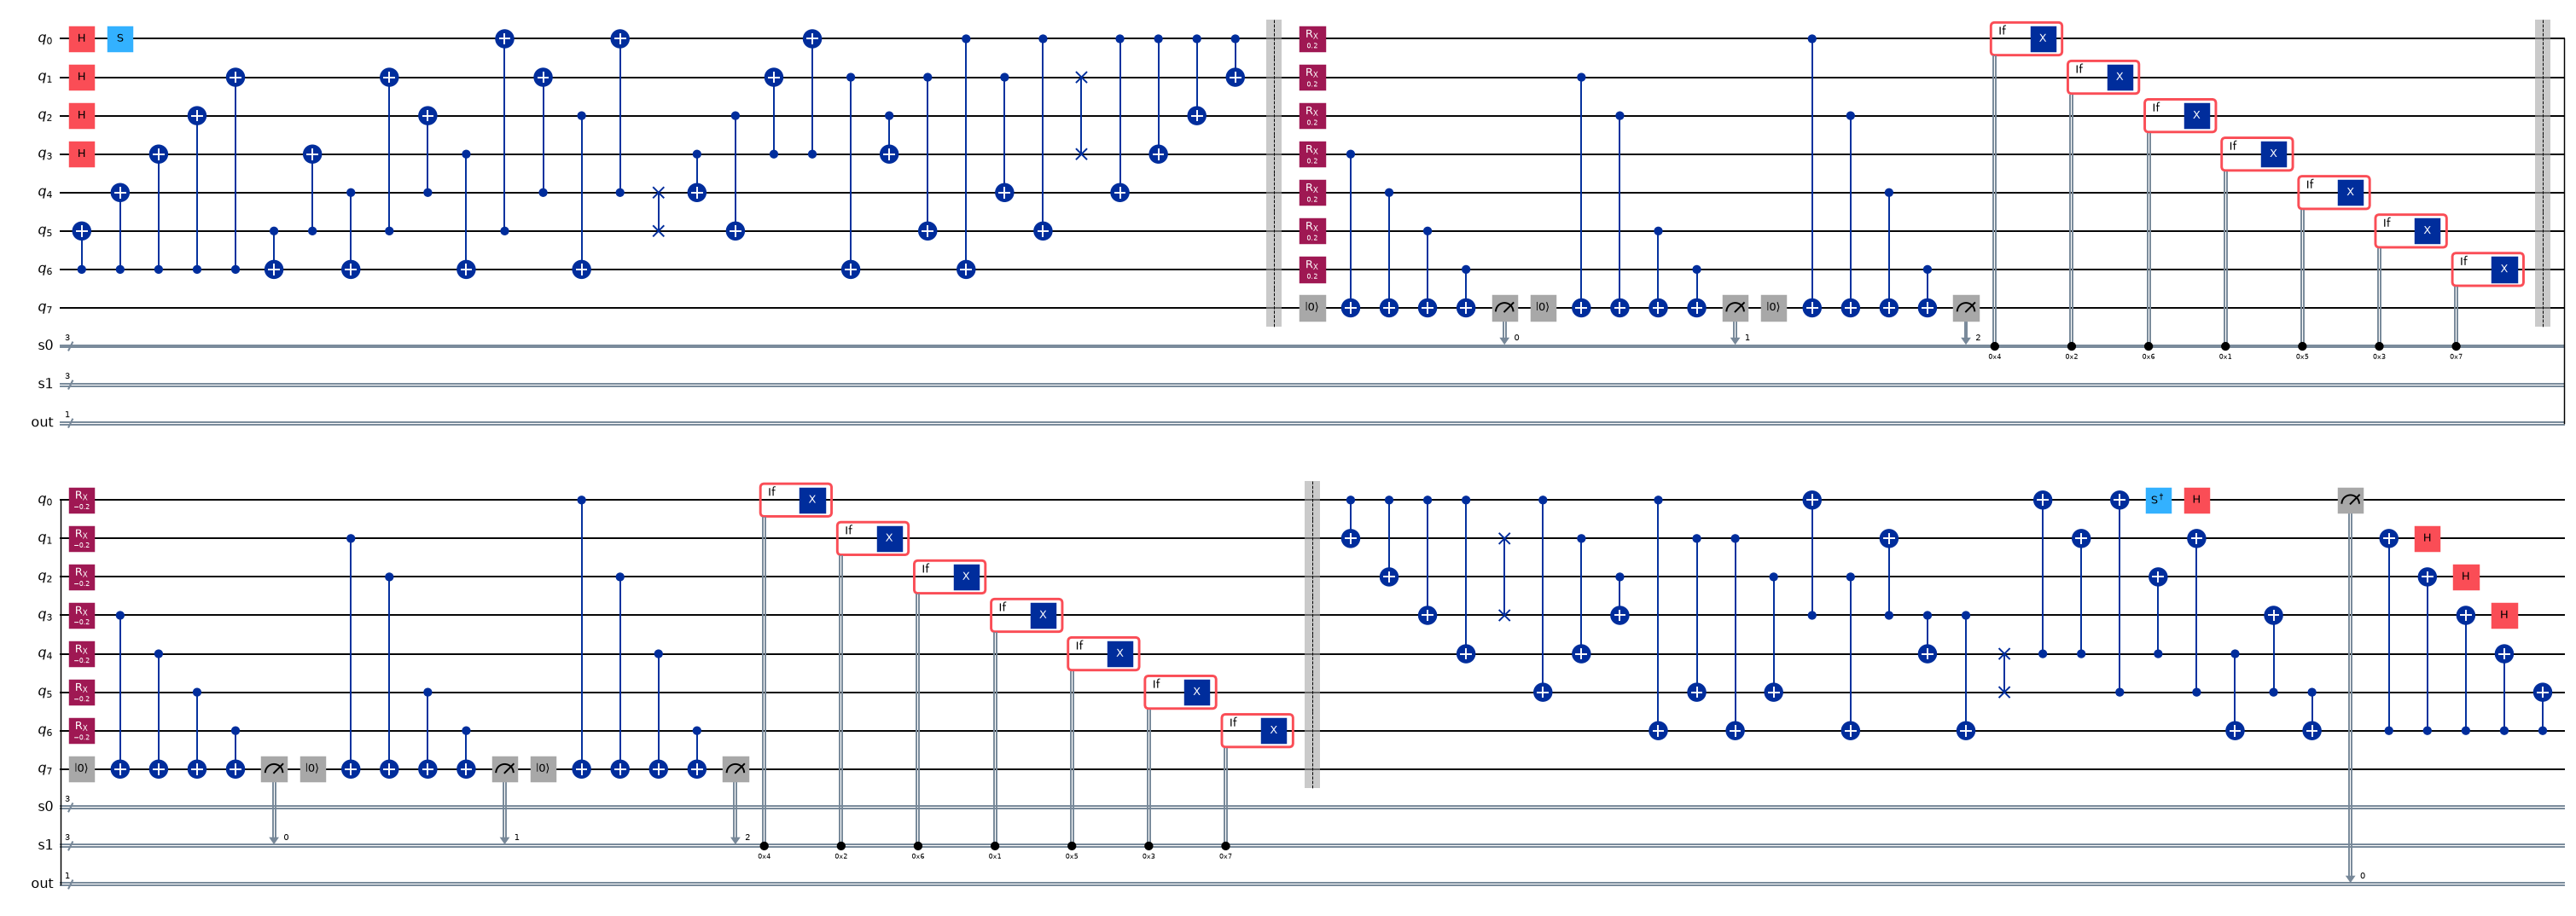

In [3]:
circuit = storage_circuit(0.1, (1, -1), state='+i')
display(circuit.draw(output='mpl', fold=65, scale=0.7))

## Execute the complete experiment

The default notebook run uses fewer shots to remain convenient. Set FULL_RUN=True for the same budgets and statistics as the main CLI. This includes all six inputs, 0/1/2/4 correction cycles, bare and ideal controls, syndrome-report sensitivity, fresh Qiskit calibration, and paired held-out logical-model comparisons. The four decoders receive exactly the same evaluation records. The angle is known to all decoders that use it; only F versus R is learned.

In [4]:
from q3hack.experiment import Config, run
FULL_RUN = False
config = Config() if FULL_RUN else Config(short_shots=256, calibration_repeats=4,
    evaluation_shots=512, bootstrap_repeats=200, budgets=(0, 128, 512))
OUTPUT = ROOT / 'results' / 'notebook-run'
manifest = run(OUTPUT, config)
print(manifest['accounting'])

Qiskit branch validation passed; executing short repeated-QEC circuits.


Short-circuit settings completed: 8/21


Short-circuit settings completed: 16/21


Short dynamic circuits passed. Running independent Qiskit calibration batches.


Calibration/evaluation: theta=0.1, model=F, N=0


...

Calibration/evaluation: theta=0.05, model=R, N=0


Calibration/evaluation: theta=0.05, model=R, N=128

Calibration/evaluation: theta=0.05, model=R, N=512


Complete: G:\qtum\q3hack-26\q3hack26-team-bells-pair\results\notebook-run (23.2 s)


{'qiskit_storage_shots': 32256, 'qiskit_calibration_shots': 13312, 'qiskit_bare_shots': 26112, 'qiskit_circuits': 1074, 'qiskit_execution_and_transpile_seconds': 19.600723705720156, 'logical_evaluation_records': 8192, 'logical_sampling_seconds': 0.00496590044349432, 'decoder_scoring_seconds': 0.014068099204450846, 'bootstrap_seconds': 0.04156109970062971}


## Read the evidence and its cost

Exact curves have no shot error bars. Calibration-budget plots use 95% paired hierarchical bootstrap intervals, including between-batch calibration variation. Four notebook batches are too few for precise risk estimates; use the full run for interpretation. The exact finite-binomial expectation is also plotted. A calibration budget that is too small can select the wrong recovery. In the full run at theta=.1,T=128,N=128, observed Fe=.8238 but exact finite-calibration expectation=.807603: all 24 batches happened to select correctly. An empirical bootstrap cannot include mistakes absent from those batches.

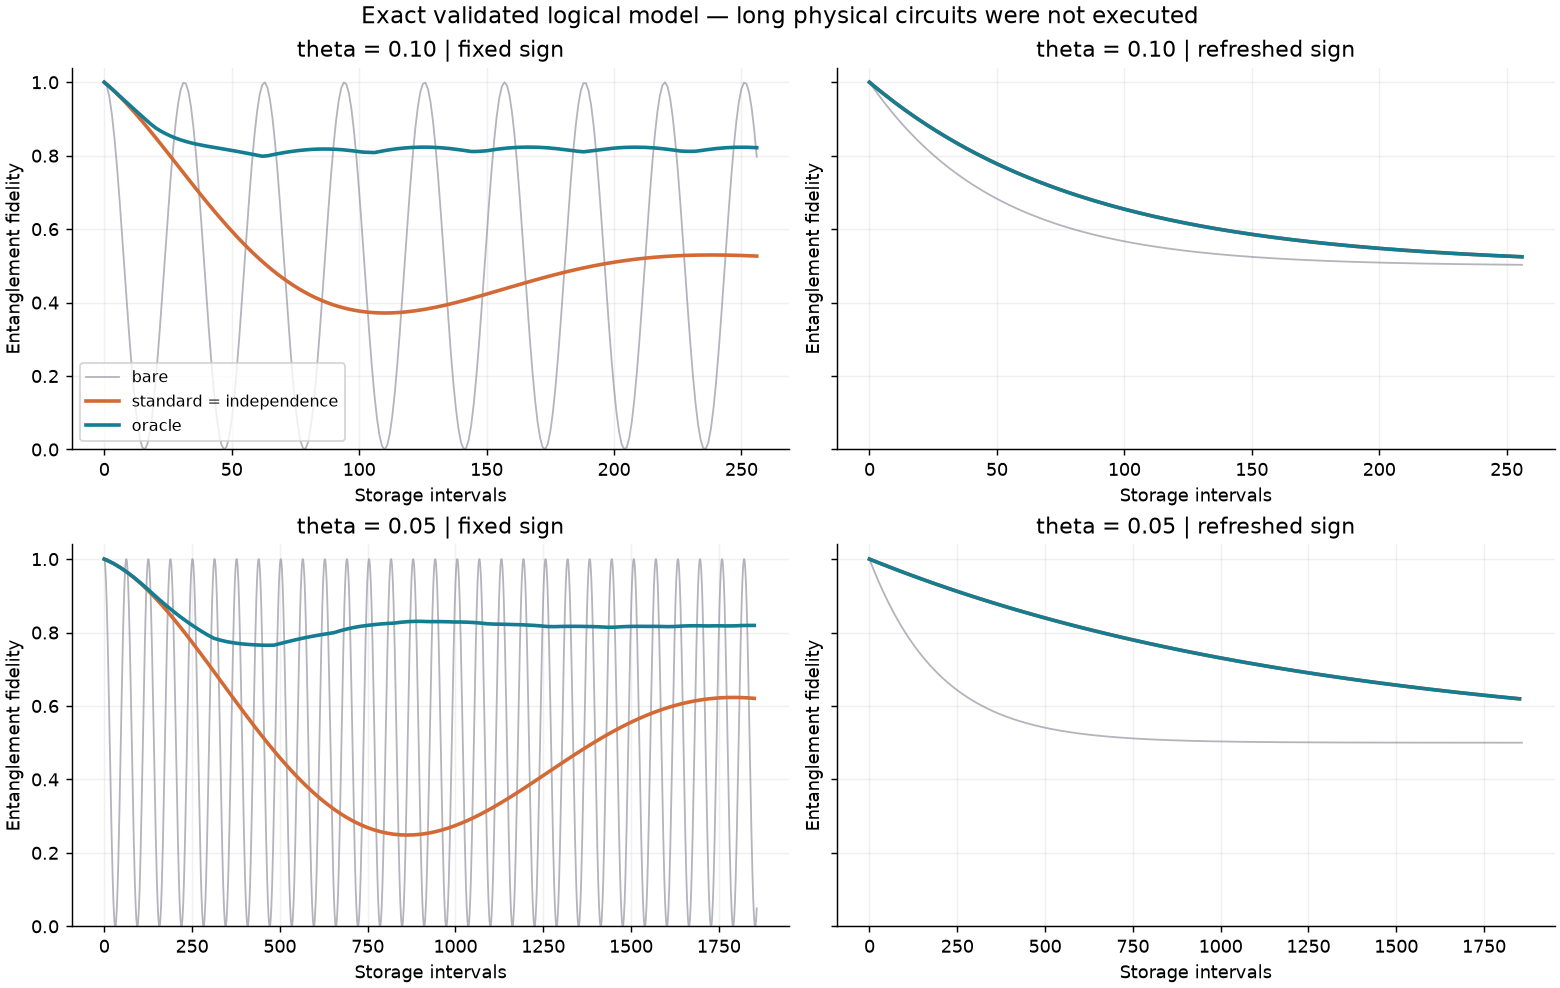

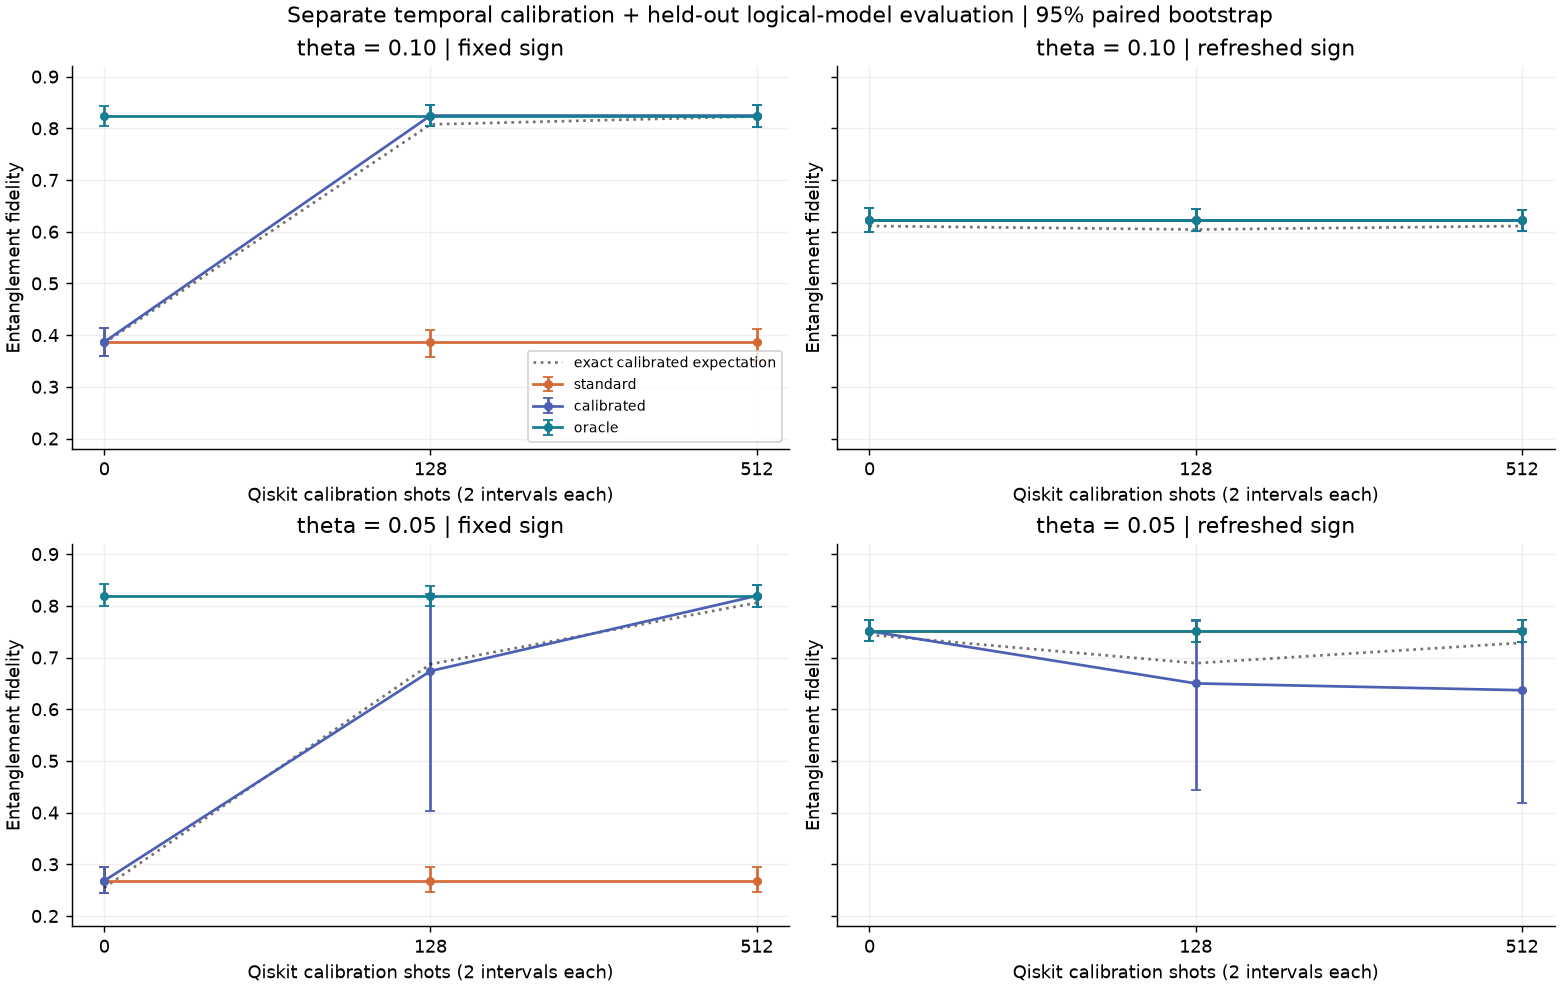

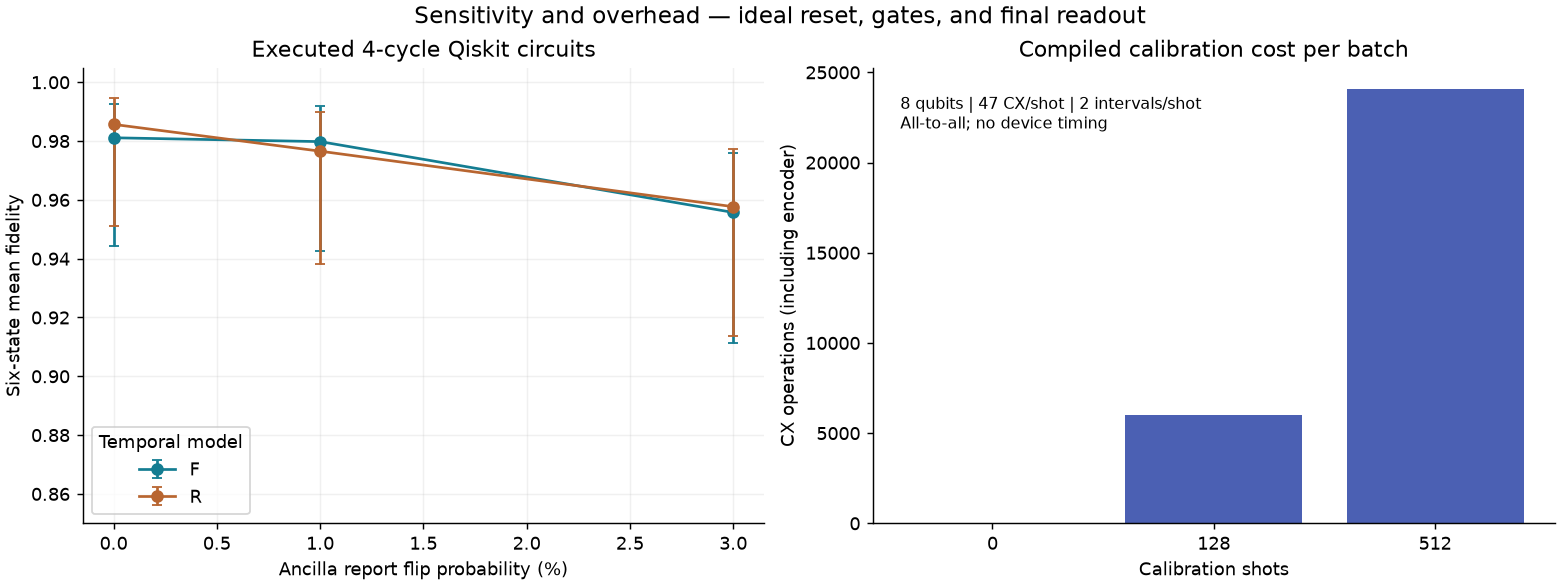

# Executed MVP results

Known-angle coherent X-noise experiment with otherwise ideal operations. Long storage uses the Qiskit-validated logical model; only 0, 1, 2, and 4 repeated-correction cycles were executed as full quantum circuits.

**F and R both contain injected rotations.** Main storage, bare controls and calibration use Aer without an added NoiseModel. Only the short sensitivity test adds ancilla report flips. See [noise settings and I/O](../docs/noise-and-io.md).

| theta | cycles | true model | calibration shots/batch | decoder | observed Fe [95% CI] | exact expected Fe | gain over standard [95% CI] |
|---:|---:|:---:|---:|:---|:---|---:|:---|
| 0.1 | 128 | F | 0 | calibrated | 0.3867 [0.3593, 0.4141] | 0.384512 | 0.0000 [0.0000, 0.0000] |
| 0.1 | 128 | F | 128 | calibrated | 0.8247 [0.8042, 0.8457] | 0.807603 | 0.4380 [0.4081, 0.4747] |
| 0.1 | 128 | F | 512 | standard | 0.3867 [0.3496, 0.4111] | 0.384512 | 0.0000 [0.0000, 0.0000] |
| 0.1 | 128 | F | 512 | calibrated | 0.8247 [0.8032, 0.8447] | 0.822941 | 0.4380 [0.4057, 0.4693] |
| 0.1 | 128 | F | 512 | oracle | 0.8247 [0.8032, 0.8447] | 0.823052 | 0.4380 [0.4057, 0.4693] |
| 0.1 | 128 | R | 0 | calibrated | 0.6235 [0.6001, 0.6461] | 0.611117 | 0.0000 [0.0000, 0.0000] |
| 0.1 | 128 | R | 128 | calibrated | 0.6235 [0.6011, 0.6441] | 0.604249 | 0.0000 [0.0000, 0.0000] |
| 0.1 | 128 | R | 512 | standard | 0.6235 [0.6015, 0.6421] | 0.611117 | 0.0000 [0.0000, 0.0000] |
| 0.1 | 128 | R | 512 | calibrated | 0.6235 [0.6015, 0.6421] | 0.611076 | 0.0000 [0.0000, 0.0000] |
| 0.1 | 128 | R | 512 | oracle | 0.6235 [0.6015, 0.6421] | 0.611117 | 0.0000 [0.0000, 0.0000] |
| 0.05 | 929 | F | 0 | calibrated | 0.2681 [0.2451, 0.2949] | 0.254879 | 0.0000 [0.0000, 0.0000] |
| 0.05 | 929 | F | 128 | calibrated | 0.6738 [0.4023, 0.8223] | 0.687190 | 0.4058 [0.1427, 0.5641] |
| 0.05 | 929 | F | 512 | standard | 0.2681 [0.2466, 0.2950] | 0.254879 | 0.0000 [0.0000, 0.0000] |
| 0.05 | 929 | F | 512 | calibrated | 0.8193 [0.7973, 0.8404] | 0.805976 | 0.5513 [0.5122, 0.5840] |
| 0.05 | 929 | F | 512 | oracle | 0.8193 [0.7973, 0.8404] | 0.829665 | 0.5513 [0.5122, 0.5840] |
| 0.05 | 929 | R | 0 | calibrated | 0.7510 [0.7319, 0.7730] | 0.743822 | 0.0000 [0.0000, 0.0000] |
| 0.05 | 929 | R | 128 | calibrated | 0.6499 [0.4428, 0.7715] | 0.688986 | -0.1011 [-0.3034, 0.0000] |
| 0.05 | 929 | R | 512 | standard | 0.7510 [0.7309, 0.7734] | 0.743822 | 0.0000 [0.0000, 0.0000] |
| 0.05 | 929 | R | 512 | calibrated | 0.6367 [0.4189, 0.7549] | 0.728451 | -0.1143 [-0.3463, 0.0000] |
| 0.05 | 929 | R | 512 | oracle | 0.7510 [0.7309, 0.7734] | 0.743822 | 0.0000 [0.0000, 0.0000] |

Fe is entanglement fidelity. For the ideal I/X channel it also equals Z-input survival. The six-state mean is (2 Fe + 1)/3. The standard and independence-assuming decisions coincide at these parameters.

The same held-out records score all four decoders, and the same evaluation batches are reused across calibration budgets. Confidence intervals include empirical calibration-batch variation and paired evaluation shot resampling. They are approximate and can be conservative; if all batches select the same model they do not reveal unobserved rare misclassification. The exact finite-binomial expectations shown beside the observations provide that check. In the full 24-batch release run for F at theta=.1, T=128, N=128, all batches selected correctly: observed Fe=.8238 but expected Fe=.807603. At N=512, expected Fe=.822941. Calibration budgets are per batch, amortized over separate held-out records.

## Short-circuit sensitivity

| true model | ancilla report flip | mean six-state fidelity [conservative 95% CI] | ideal prediction |
|:---:|---:|:---|---:|
| F | 0.00% | 0.9811 [0.9442, 0.9925] | 0.9835 |
| R | 0.00% | 0.9857 [0.9510, 0.9946] | 0.9847 |
| F | 1.00% | 0.9798 [0.9425, 0.9918] | 0.9835 |
| F | 3.00% | 0.9557 [0.9112, 0.9761] | 0.9835 |
| R | 1.00% | 0.9766 [0.9381, 0.9898] | 0.9847 |
| R | 3.00% | 0.9577 [0.9138, 0.9773] | 0.9847 |

Only syndrome reports have the added flip probability; other gates, reset, and final readout remain ideal. The reduced model is not used to predict this disturbed circuit. The oracle label in sensitivity rows means an ideal-model oracle, not an optimal noisy-circuit decoder. Calibration probes remain ideal, so this does not test calibration robustness.

## Cost and scope

- Qiskit storage shots: 32,256.
- Qiskit calibration shots: 13,312 (26,624 physical noise intervals).
- Qiskit bare-memory shots: 26,112.
- Unique long logical-model evaluation records: 8,192.
- Total pipeline time: 23.2 seconds on the recorded host.
- Long-model sampling: 0.005 s; decoder scoring: 0.014 s; bootstrap: 0.04 s. These are host computation times, not physical storage times.
- Storage uses seven data qubits plus one reusable ancilla. Each cycle has 12 CX, 3 resets, 3 syndrome measurements, and at most one executed conditional X. The final decoder is a destructive-readout Pauli frame with no added quantum gates.
- Calibration at N shots costs 2N noise intervals, N encoder preparations, 12N extraction CX, 3N resets and 3N measurements. Full compiled totals, including encoder/decoder, are in resources.json.
- No QPU, routing, gate timing, general fault tolerance, unknown-angle estimation, bath witness, or long physical-circuit performance was established.

## Track 3 interpretation

The known answer is preservation of an arbitrary encoded qubit. Zero-noise controls, noisy storage, a fixed correction circuit, and calibrated final recovery are supplied with measured and modeled costs. Syndrome agreement alone does not establish recovery reliability in this constructed example. Calibration is worth its cost when it changes a consequential decision; it gives little benefit at short times or when the independence assumption already holds. This is a simulator demonstration of evidence needed for trust, not a claim of device readiness or a new error-correction theorem.

Reproduction commands and mathematical assumptions are in ../README.md and ../docs/math-note.md. The proposed path to devices and application metrics is in [hardware and workloads](../docs/hardware-workloads.md).


In [5]:
display(Image(filename=str(OUTPUT / 'storage_fidelity.png')))
display(Image(filename=str(OUTPUT / 'calibration_budget.png')))
display(Image(filename=str(OUTPUT / 'cost_sensitivity.png')))
display(Markdown((OUTPUT / 'REPORT.md').read_text(encoding='utf-8')))

## Exact decision-sensitive checkpoints

These values are model calculations, not additional Qiskit shots. These two points were fixed before evaluation.

In [6]:
for theta, cycles in ((0.1, 128), (0.05, 929)):
    print({'theta': theta, 'cycles': cycles,
        'F standard Fe': exact_fidelity(theta, cycles, 'F'),
        'F oracle Fe': exact_fidelity(theta, cycles, 'F', 'F'),
        'R oracle Fe': exact_fidelity(theta, cycles, 'R', 'R')})
print('Run outputs and parameters:', OUTPUT / 'manifest.json')

{'theta': 0.1, 'cycles': 128, 'F standard Fe': 0.38451217313263075, 'F oracle Fe': 0.823051527332987, 'R oracle Fe': 0.6111174360311356}
{'theta': 0.05, 'cycles': 929, 'F standard Fe': 0.25487937414738193, 'F oracle Fe': 0.8296646494228168, 'R oracle Fe': 0.74382207664545}
Run outputs and parameters: G:\qtum\q3hack-26\q3hack26-team-bells-pair\results\notebook-run\manifest.json


## Interpretation and limits

A common sign within each interval makes both models spatially correlated. Only its persistence across intervals differs. Ordinary syndrome histories have identical distributions in the ideal construction, while delayed extraction supplies temporal information. Calibration leaves the storage circuit unchanged.

Entanglement fidelity Fe differs from the six-state mean Favg=(2 Fe+1)/3. Only for the ideal I/X channel does Z-input survival equal Fe. Ancilla-report errors break the ideal branch assumptions. No unknown-angle fit, quantum bath, formal memory witness, hardware threshold, or long physical circuit is claimed.

Academic foundations: [Steane 1996](https://arxiv.org/abs/quant-ph/9601029), [Morales-Hashemi et al. 2026, v1](https://arxiv.org/abs/2610.03545v1), [Nielsen 2002](https://arxiv.org/abs/quant-ph/0205035), [Hockings et al. 2025, v2](https://arxiv.org/abs/2502.21044v2). The full source/claim mapping is in the mathematical note.

## Modern hardware and workloads

This is an encoded **storage** benchmark. IBM dynamic circuits provide the same measurement/feedforward ingredients, but a device translation must account for connectivity, native gates, reset and measurement faults, and controller latency. Compiled depth here is not elapsed device time. [IBM dynamic circuits](https://quantum.cloud.ibm.com/docs/en/guides/execute-dynamic-circuits).

Chemistry workflows such as SQD sample quantum states and estimate energies through classical processing. Our proposed connection is independent diagnostics and held-out validation at matched cost. Better memory fidelity alone does not prove better energy estimates; no active application workload was run. [IBM SQD](https://quantum.cloud.ibm.com/docs/en/addons/qiskit-addon-sqd). See the [device and workload plan](../docs/hardware-workloads.md).